In [2]:
import pandas as pd

# Đọc dữ liệu đã xử lý
df = pd.read_csv("../data/processed/online_retail_cleaned.csv")

# Đọc dữ liệu sales
df_sales = pd.read_csv("../data/processed/online_retail_sales.csv")

print("Dữ liệu cleaned:", df.shape)
print("Dữ liệu sales:", df_sales.shape)

display(df_sales.head())
df_sales["Revenue"] = df_sales["Quantity"] * df_sales["Price"]

print("Tổng doanh thu:", df_sales["Revenue"].sum())

Dữ liệu cleaned: (1055238, 12)
Dữ liệu sales: (1029609, 13)


C:\Users\minh\AppData\Local\Temp\ipykernel_4920\1523997057.py:7: DtypeWarning: Columns (0: Invoice) have mixed types. Specify dtype option on import or set low_memory=False.
  df_sales = pd.read_csv("../data/processed/online_retail_sales.csv")


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,SourceSheet,IsCancelled,IsSpecialAdjustment,IsNegativePrice,Revenue
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,Year 2009-2010,False,False,False,83.4
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,Year 2009-2010,False,False,False,81.0
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,Year 2009-2010,False,False,False,81.0
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,Year 2009-2010,False,False,False,100.8
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,Year 2009-2010,False,False,False,30.0


Tổng doanh thu: 20913891.468000002


In [3]:

# Top 10 giao dịch có doanh thu cao nhất
top_revenue = df_sales.sort_values(
    by="Revenue",
    ascending=False
).head(10)

display(
    top_revenue[
        ["Invoice", "Description", "Quantity", "Price", "Revenue", "Country"]
    ]
)


,Invoice,Description,Quantity,Price,Revenue,Country
1028134,581483,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,168469.60,United Kingdom
564379,541431,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,77183.60,United Kingdom
720195,556444,PICNIC BASKET WICKER 60 PIECES,60,649.50,38970.00,United Kingdom
231523,512771,Manual,1,25111.09,25111.09,United Kingdom
414827,530715,ROTATING SILVER ANGELS T-LIGHT HLDR,9360,1.69,15818.40,United Kingdom
497490,537632,AMAZON FEE,1,13541.33,13541.33,United Kingdom
519186,537632,AMAZON FEE,1,13541.33,13541.33,United Kingdom
795236,A563185,Adjust bad debt,1,11062.06,11062.06,United Kingdom
129382,502263,Manual,1,10953.50,10953.50,United Kingdom
129383,502265,Manual,1,10953.50,10953.50,United Kingdom


In [4]:

# Thống kê tổng quan doanh thu
print("Tổng doanh thu:", df_sales["Revenue"].sum())
print("Doanh thu trung bình:", df_sales["Revenue"].mean())
print("Doanh thu trung vị:", df_sales["Revenue"].median())
print("Doanh thu lớn nhất:", df_sales["Revenue"].max())
print("Doanh thu nhỏ nhất:", df_sales["Revenue"].min())


Tổng doanh thu: 20913891.468000002
Doanh thu trung bình: 20.31245984446523
Doanh thu trung vị: 10.08
Doanh thu lớn nhất: 168469.6
Doanh thu nhỏ nhất: 0.001


In [5]:

# Kiểm tra tên các cột
print(df_sales.columns.tolist())

# Kiểm tra kiểu dữ liệu
print(df_sales.dtypes)

# Xem thử 10 giá trị ngày tháng
display(df_sales[["InvoiceDate"]].head(10))


['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country', 'SourceSheet', 'IsCancelled', 'IsSpecialAdjustment', 'IsNegativePrice', 'Revenue']
Invoice                 object
StockCode                  str
Description                str
Quantity                 int64
InvoiceDate                str
Price                  float64
Customer ID            float64
Country                    str
SourceSheet                str
IsCancelled               bool
IsSpecialAdjustment       bool
IsNegativePrice           bool
Revenue                float64
dtype: object


,InvoiceDate
0,2009-12-01 07:45:00
1,2009-12-01 07:45:00
2,2009-12-01 07:45:00
3,2009-12-01 07:45:00
4,2009-12-01 07:45:00
5,2009-12-01 07:45:00
6,2009-12-01 07:45:00
7,2009-12-01 07:45:00
8,2009-12-01 07:46:00
9,2009-12-01 07:46:00


In [7]:

# Chuyển InvoiceDate sang kiểu datetime
df_sales["InvoiceDate"] = pd.to_datetime(
    df_sales["InvoiceDate"],
    errors="coerce"
)

# Tạo cột tháng
df_sales["Month"] = df_sales["InvoiceDate"].dt.to_period("M")

# Kiểm tra kết quả
print("Số ngày tháng không hợp lệ:",
      df_sales["InvoiceDate"].isna().sum())

display(
    df_sales[["InvoiceDate", "Month", "Revenue"]].head(10)
)

# Tính tổng doanh thu từng tháng
monthly_revenue = df_sales.groupby("Month")["Revenue"].sum()

display(monthly_revenue)


Số ngày tháng không hợp lệ: 0


,InvoiceDate,Month,Revenue
0,2009-12-01 07:45:00,2009-12,83.4
1,2009-12-01 07:45:00,2009-12,81.0
2,2009-12-01 07:45:00,2009-12,81.0
3,2009-12-01 07:45:00,2009-12,100.8
4,2009-12-01 07:45:00,2009-12,30.0
5,2009-12-01 07:45:00,2009-12,39.6
6,2009-12-01 07:45:00,2009-12,30.0
7,2009-12-01 07:45:00,2009-12,59.5
8,2009-12-01 07:46:00,2009-12,30.6
9,2009-12-01 07:46:00,2009-12,45.0


Month
2009-12     822483.950
2010-01     651155.112
2010-02     551504.726
2010-03     830915.261
2010-04     678875.252
2010-05     657705.500
2010-06     749537.310
2010-07     648810.270
2010-08     695251.910
2010-09     921696.991
2010-10    1161902.220
2010-11    1464293.142
2010-12    1259083.750
2011-01     689811.610
2011-02     522545.560
2011-03     716215.260
2011-04     536968.491
2011-05     769296.610
2011-06     760547.010
2011-07     718076.121
2011-08     757841.380
2011-09    1056435.192
2011-10    1151263.730
2011-11    1503866.780
2011-12     637808.330
Freq: M, Name: Revenue, dtype: float64

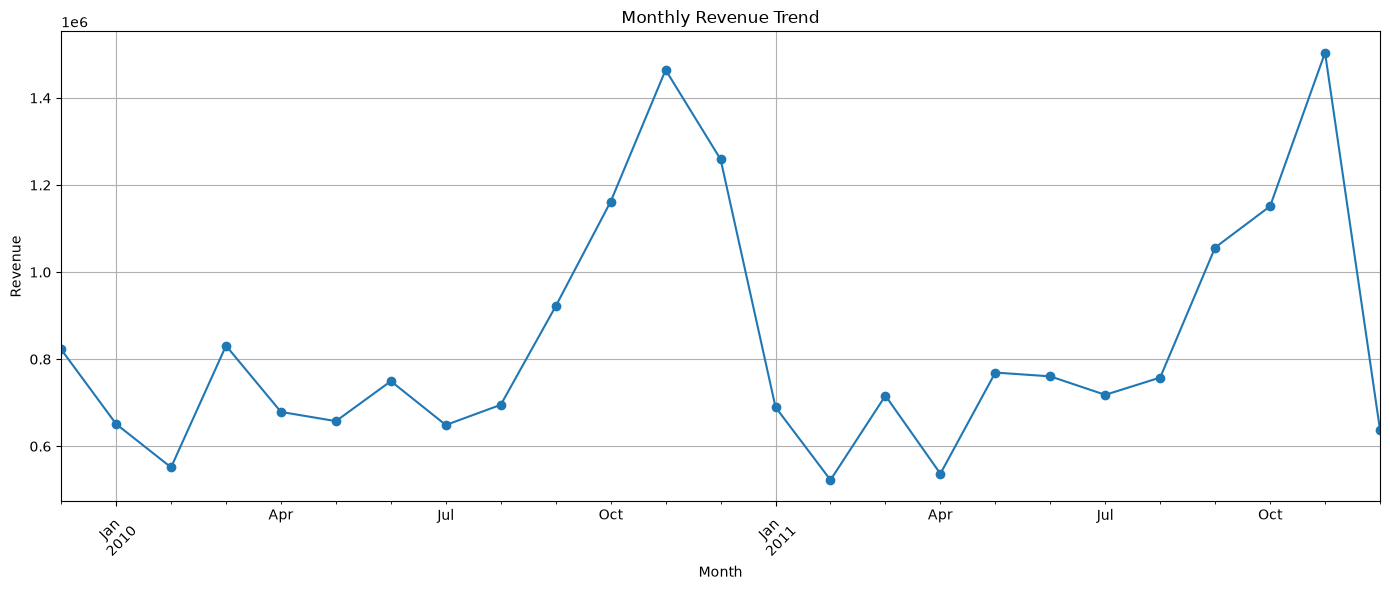

In [8]:

import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

monthly_revenue.plot(kind="line", marker="o")

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()


Biến động giữa các tháng

Có, và biến động mang tính mùa vụ rõ rệt:

Giai đoạn đầu năm đến giữa năm (tháng 1 đến 8): doanh thu thấp và dao động nhẹ quanh 0,5 đến 0,8 triệu.
Giai đoạn cuối năm (tháng 9 đến 11): doanh thu tăng mạnh, gấp khoảng 2 lần mức nền, đạt đỉnh vào tháng 11.
Sau đỉnh: doanh thu giảm sốc vào tháng 12 (từ ~1,46 triệu xuống ~1,26 triệu năm 2010) và tiếp tục giảm mạnh sau đó.
Quy luật này lặp lại ở cả hai năm, cho thấy yếu tố mùa vụ (mua sắm cuối năm, lễ hội).

In [9]:

# Tổng hợp doanh thu theo quốc gia
country_revenue = df_sales.groupby("Country").agg(
    Total_Revenue=("Revenue", "sum"),
    Total_Quantity=("Quantity", "sum"),
    Total_Invoices=("Invoice", "nunique"),
    Total_Customers=("Customer ID", "nunique")
).sort_values(
    by="Total_Revenue",
    ascending=False
)

# Hiển thị 10 quốc gia có doanh thu cao nhất
display(country_revenue.head(10))


,Total_Revenue,Total_Quantity,Total_Invoices,Total_Customers
Country,,,,
United Kingdom,1.781406e+07,9349186,36537,5350
EIRE,6.640501e+05,340054,626,5
Netherlands,5.542307e+05,383976,228,22
Germany,4.307038e+05,227769,789,107
France,3.567465e+05,275090,622,95
Australia,1.699006e+05,104080,95,15
Spain,1.091272e+05,50774,154,41
Switzerland,1.009890e+05,52872,93,22
Sweden,9.186982e+04,88633,105,19


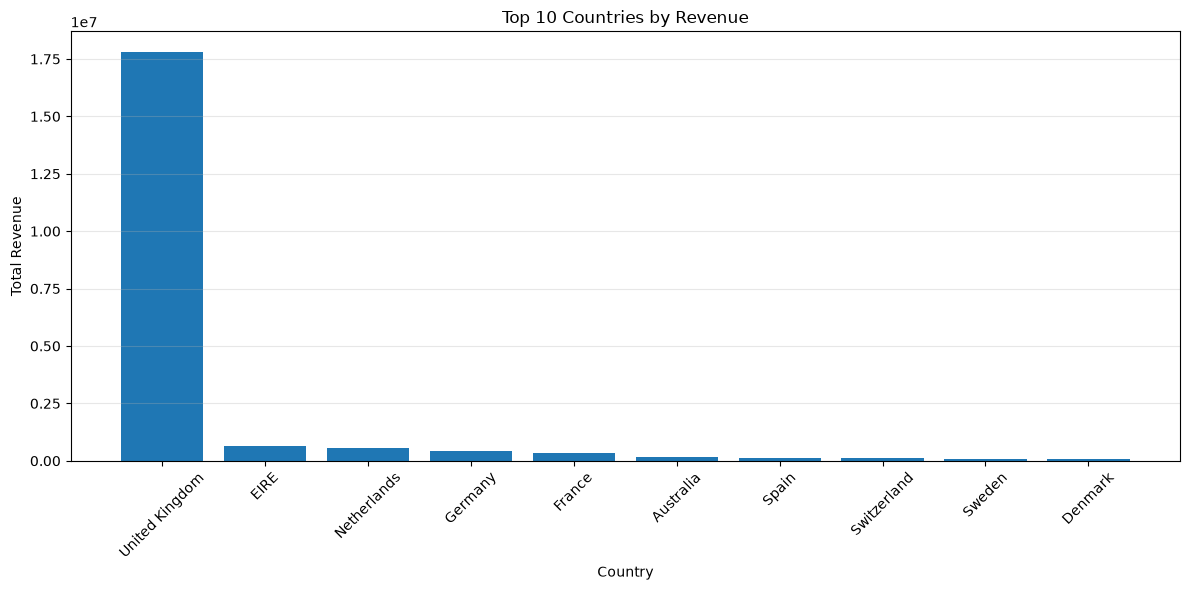

In [10]:

import matplotlib.pyplot as plt

top_10_countries = country_revenue.head(10)

plt.figure(figsize=(12, 6))

plt.bar(
    top_10_countries.index,
    top_10_countries["Total_Revenue"]
)

plt.title("Top 10 Countries by Revenue")
plt.xlabel("Country")
plt.ylabel("Total Revenue")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


In [11]:

total_revenue = country_revenue["Total_Revenue"].sum()

country_revenue["Revenue_Percentage"] = (
    country_revenue["Total_Revenue"] / total_revenue * 100
)

display(
    country_revenue[
        ["Total_Revenue", "Revenue_Percentage"]
    ].head(10)
)


,Total_Revenue,Revenue_Percentage
Country,,
United Kingdom,1.781406e+07,85.178103
EIRE,6.640501e+05,3.175163
Netherlands,5.542307e+05,2.650060
Germany,4.307038e+05,2.059415
France,3.567465e+05,1.705787
Australia,1.699006e+05,0.812382
Spain,1.091272e+05,0.521793
Switzerland,1.009890e+05,0.482880
Sweden,9.186982e+04,0.439277


In [12]:

# Loại bỏ các dòng không có tên sản phẩm
df_product = df_sales.dropna(subset=["Description"]).copy()

# Thống kê theo sản phẩm
product_analysis = df_product.groupby("Description").agg(
    Total_Quantity=("Quantity", "sum"),
    Total_Revenue=("Revenue", "sum"),
    Total_Invoices=("Invoice", "nunique")
).sort_values(
    by="Total_Quantity",
    ascending=False
)

# Top 10 sản phẩm bán chạy
top_10_quantity = product_analysis.head(10)

display(top_10_quantity)


,Total_Quantity,Total_Revenue,Total_Invoices
Description,,,
WORLD WAR 2 GLIDERS ASSTD DESIGNS,109898,25197.98,1019
WHITE HANGING HEART T-LIGHT HOLDER,96563,266582.35,5455
ASSORTED COLOUR BIRD ORNAMENT,81590,131817.81,2807
"PAPER CRAFT , LITTLE BIRDIE",80995,168469.60,1
JUMBO BAG RED RETROSPOT,79117,150640.27,3269
MEDIUM CERAMIC TOP STORAGE JAR,78033,81700.92,247
BROCADE RING PURSE,71394,14948.75,456
PACK OF 60 PINK PAISLEY CAKE CASES,56625,28413.63,1993
60 TEATIME FAIRY CAKE CASES,54537,27321.37,2127


In [13]:

top_10_product_revenue = product_analysis.sort_values(
    by="Total_Revenue",
    ascending=False
).head(10)

display(top_10_product_revenue)


,Total_Quantity,Total_Revenue,Total_Invoices
Description,,,
REGENCY CAKESTAND 3 TIER,27536,344069.30,3918
Manual,9753,340342.68,788
DOTCOM POSTAGE,1436,322657.48,1415
WHITE HANGING HEART T-LIGHT HOLDER,96563,266582.35,5455
"PAPER CRAFT , LITTLE BIRDIE",80995,168469.60,1
JUMBO BAG RED RETROSPOT,79117,150640.27,3269
PARTY BUNTING,28362,149109.35,2674
ASSORTED COLOUR BIRD ORNAMENT,81590,131817.81,2807
POSTAGE,5461,127597.42,1851


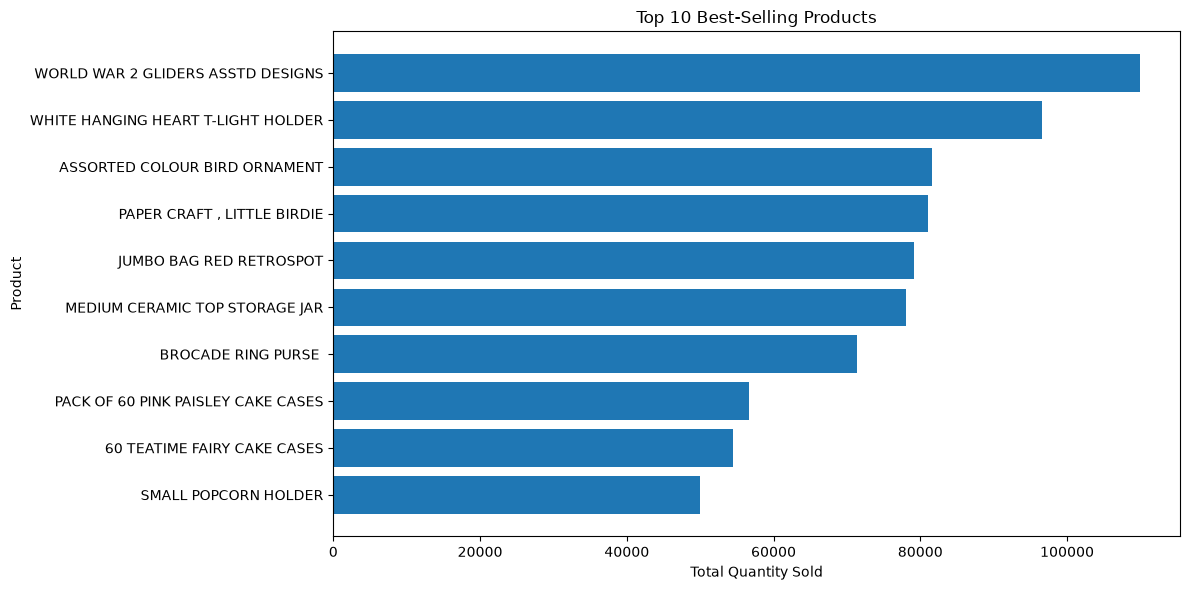

In [14]:

plt.figure(figsize=(12, 6))

plt.barh(
    top_10_quantity.index[::-1],
    top_10_quantity["Total_Quantity"].values[::-1]
)

plt.title("Top 10 Best-Selling Products")
plt.xlabel("Total Quantity Sold")
plt.ylabel("Product")

plt.tight_layout()
plt.show()


In [15]:

# Tạo bản sao dữ liệu phân tích khách hàng
df_customer = df_sales.copy()

# Chỉ giữ các giao dịch có Customer ID
df_customer = df_customer.dropna(subset=["Customer ID"])

# Kiểm tra dữ liệu
print("Kích thước dữ liệu khách hàng:", df_customer.shape)
print("Số khách hàng:", df_customer["Customer ID"].nunique())

display(df_customer.head())


Kích thước dữ liệu khách hàng: (793609, 14)
Số khách hàng: 5878


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,SourceSheet,IsCancelled,IsSpecialAdjustment,IsNegativePrice,Revenue,Month
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,Year 2009-2010,False,False,False,83.4,2009-12
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,Year 2009-2010,False,False,False,81.0,2009-12
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,Year 2009-2010,False,False,False,81.0,2009-12
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,Year 2009-2010,False,False,False,100.8,2009-12
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,Year 2009-2010,False,False,False,30.0,2009-12


In [16]:

# Tổng hợp dữ liệu theo khách hàng
customer_analysis = df_customer.groupby("Customer ID").agg(
    Total_Revenue=("Revenue", "sum"),
    Total_Quantity=("Quantity", "sum"),
    Total_Invoices=("Invoice", "nunique")
).sort_values(
    by="Total_Revenue",
    ascending=False
)

# Top 10 khách hàng có doanh thu cao nhất
top_10_customers = customer_analysis.head(10)

display(top_10_customers)


,Total_Revenue,Total_Quantity,Total_Invoices
Customer ID,,,
18102.0,608821.65,188340,145
14646.0,528602.52,367193,151
14156.0,313759.82,165873,156
14911.0,295832.39,149949,398
17450.0,246813.09,84700,51
13694.0,196482.81,189205,143
17511.0,175603.55,119656,60
16446.0,168472.50,80997,2
16684.0,147142.77,104810,55


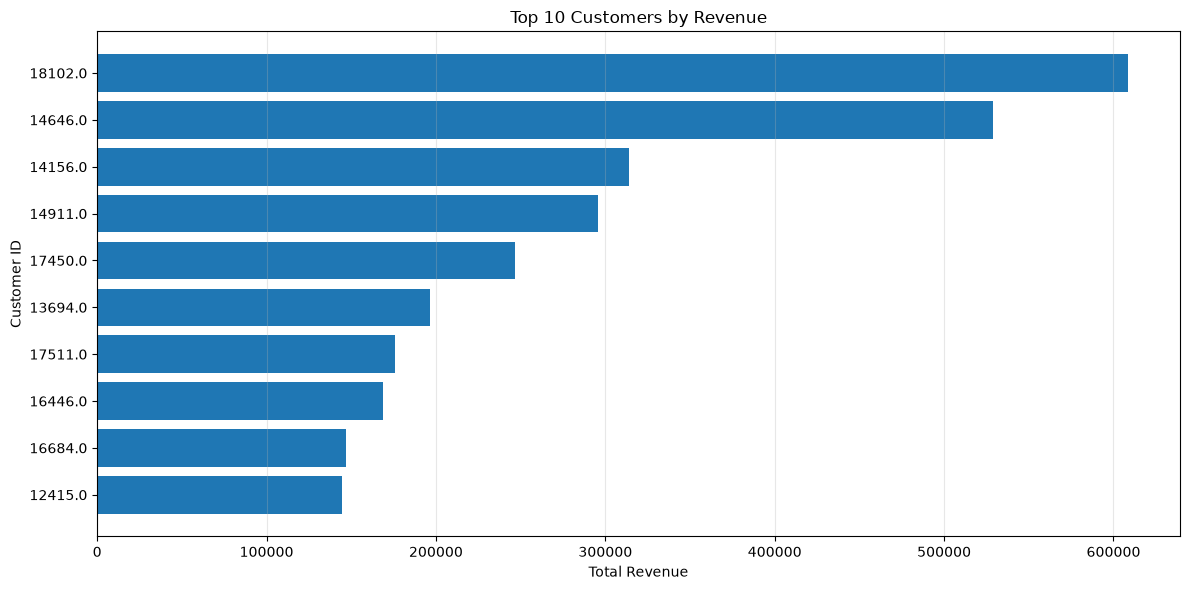

In [17]:

plt.figure(figsize=(12, 6))

plt.barh(
    top_10_customers.index.astype(str)[::-1],
    top_10_customers["Total_Revenue"].values[::-1]
)

plt.title("Top 10 Customers by Revenue")
plt.xlabel("Total Revenue")
plt.ylabel("Customer ID")

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()


In [18]:

# Tổng doanh thu của nhóm khách hàng có ID
total_customer_revenue = df_customer["Revenue"].sum()

# Doanh thu Top 10 khách hàng
top10_revenue = top_10_customers["Total_Revenue"].sum()

# Tỷ trọng
top10_percentage = top10_revenue / total_customer_revenue * 100

print("Tổng doanh thu khách hàng:", total_customer_revenue)
print("Doanh thu Top 10:", top10_revenue)
print("Tỷ trọng Top 10:", round(top10_percentage, 2), "%")


Tổng doanh thu khách hàng: 17685460.638
Doanh thu Top 10: 2825989.47
Tỷ trọng Top 10: 15.98 %


In [19]:

# Top 10 khách hàng có số hóa đơn nhiều nhất
top_invoice_customers = customer_analysis.sort_values(
    by="Total_Invoices",
    ascending=False
).head(10)

display(top_invoice_customers)


,Total_Revenue,Total_Quantity,Total_Invoices
Customer ID,,,
14911.0,295832.39,149949,398
12748.0,55511.09,38396,336
17841.0,70081.86,37166,211
15311.0,116575.49,70931,208
13089.0,116647.53,60150,203
14606.0,30558.25,15474,192
14156.0,313759.82,165873,156
17850.0,56600.08,22785,155
14646.0,528602.52,367193,151


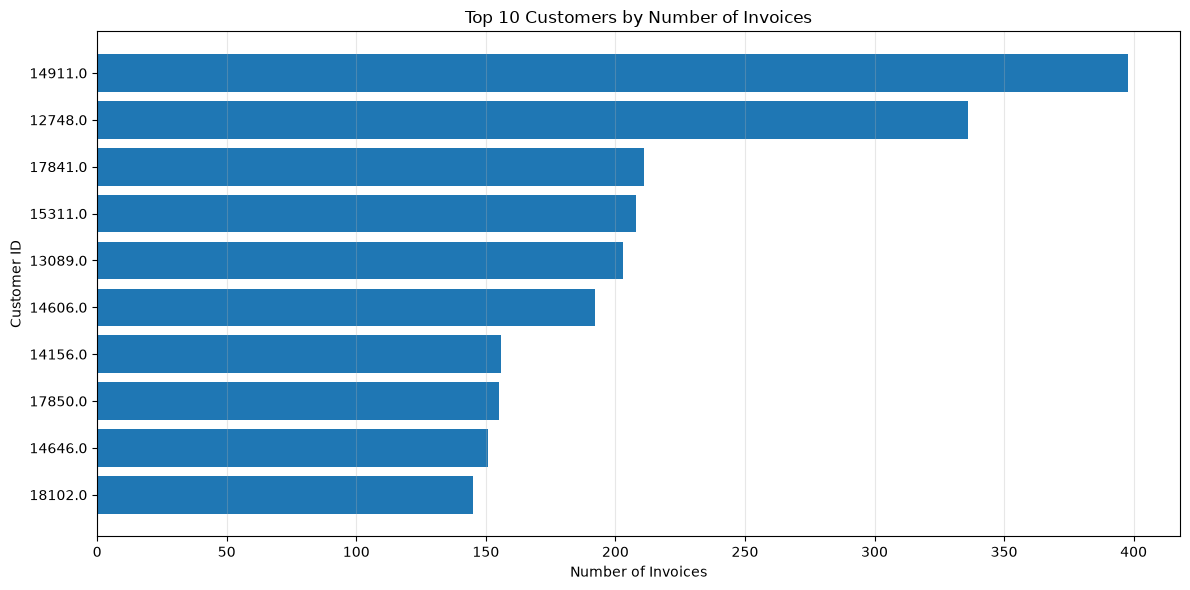

In [20]:

plt.figure(figsize=(12, 6))

plt.barh(
    top_invoice_customers.index.astype(str)[::-1],
    top_invoice_customers["Total_Invoices"].values[::-1]
)

plt.title("Top 10 Customers by Number of Invoices")
plt.xlabel("Number of Invoices")
plt.ylabel("Customer ID")

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()


In [21]:

# Tính doanh thu trung bình trên mỗi hóa đơn
customer_analysis["Average_Invoice_Value"] = (
    customer_analysis["Total_Revenue"]
    / customer_analysis["Total_Invoices"]
)

# Top 10 khách hàng có giá trị hóa đơn trung bình cao nhất
top_10_aov = customer_analysis.sort_values(
    by="Average_Invoice_Value",
    ascending=False
).head(10)

display(top_10_aov)


,Total_Revenue,Total_Quantity,Total_Invoices,Average_Invoice_Value
Customer ID,,,,
16446.0,168472.50,80997,2,84236.250000
15749.0,44534.30,18028,3,14844.766667
15098.0,39916.50,121,3,13305.500000
13687.0,11880.84,87167,1,11880.840000
12918.0,10953.50,1,1,10953.500000
18052.0,10877.18,17766,1,10877.180000
15760.0,13916.34,2,2,6958.170000
13902.0,34095.26,220600,5,6819.052000
12346.0,77556.46,74285,12,6463.038333


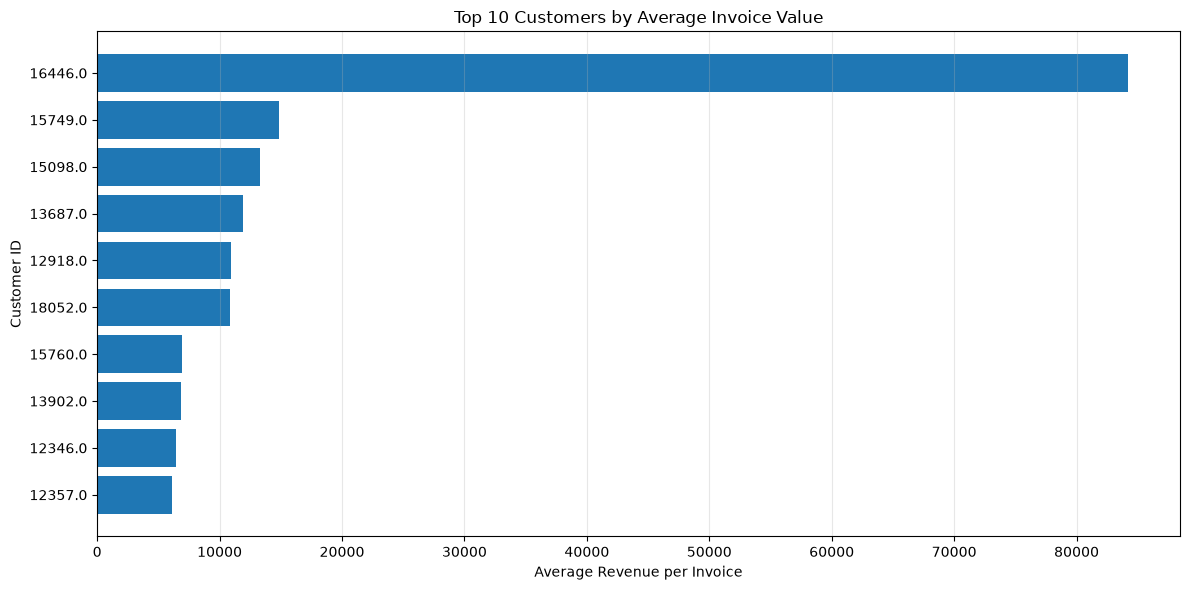

In [22]:

plt.figure(figsize=(12, 6))

plt.barh(
    top_10_aov.index.astype(str)[::-1],
    top_10_aov["Average_Invoice_Value"].values[::-1]
)

plt.title("Top 10 Customers by Average Invoice Value")
plt.xlabel("Average Revenue per Invoice")
plt.ylabel("Customer ID")

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()


In [23]:

# Thống kê Quantity và Price
display(df_sales[["Quantity", "Price"]].describe())


,Quantity,Price
count,1.029609e+06,1.029609e+06
mean,1.105795e+01,4.094842e+00
std,1.272405e+02,5.174728e+01
min,1.000000e+00,1.000000e-03
25%,1.000000e+00,1.250000e+00
50%,3.000000e+00,2.100000e+00
75%,1.200000e+01,4.150000e+00
max,8.099500e+04,2.511109e+04


In [24]:

# Kiểm tra số lượng và giá bán bất thường
print("Quantity âm:", (df_sales["Quantity"] < 0).sum())
print("Quantity bằng 0:", (df_sales["Quantity"] == 0).sum())

print("Price âm:", (df_sales["Price"] < 0).sum())
print("Price bằng 0:", (df_sales["Price"] == 0).sum())


Quantity âm: 0
Quantity bằng 0: 0
Price âm: 0
Price bằng 0: 0


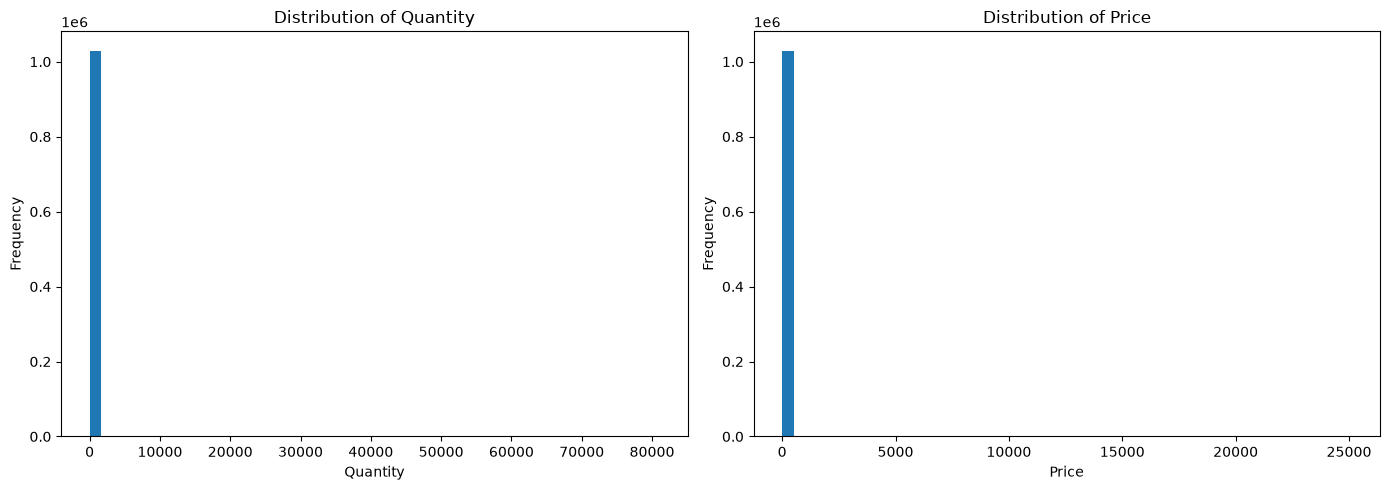

In [25]:

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(df_sales["Quantity"], bins=50)
axes[0].set_title("Distribution of Quantity")
axes[0].set_xlabel("Quantity")
axes[0].set_ylabel("Frequency")

axes[1].hist(df_sales["Price"], bins=50)
axes[1].set_title("Distribution of Price")
axes[1].set_xlabel("Price")
axes[1].set_ylabel("Frequency")

plt.tight_layout()
plt.show()


In [26]:

# Hàm tính giới hạn IQR
def check_iqr(df, column):
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ]

    print(f"--- {column} ---")
    print("Q1:", Q1)
    print("Q3:", Q3)
    print("IQR:", IQR)
    print("Lower bound:", lower_bound)
    print("Upper bound:", upper_bound)
    print("Số outlier:", len(outliers))
    print("Tỷ lệ outlier:", round(len(outliers) / len(df) * 100, 2), "%")

    return outliers

# Kiểm tra Quantity và Price
outliers_quantity = check_iqr(df_sales, "Quantity")
outliers_price = check_iqr(df_sales, "Price")


--- Quantity ---
Q1: 1.0
Q3: 12.0
IQR: 11.0
Lower bound: -15.5
Upper bound: 28.5
Số outlier: 53926
Tỷ lệ outlier: 5.24 %
--- Price ---
Q1: 1.25
Q3: 4.15
IQR: 2.9000000000000004
Lower bound: -3.1000000000000005
Upper bound: 8.5
Số outlier: 64672
Tỷ lệ outlier: 6.28 %


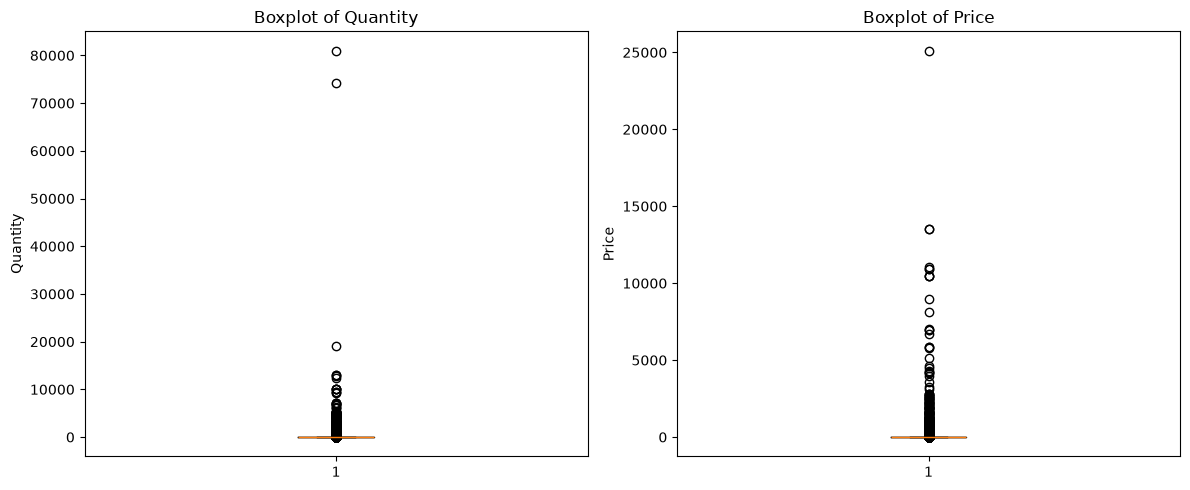

In [27]:

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].boxplot(df_sales["Quantity"])
axes[0].set_title("Boxplot of Quantity")
axes[0].set_ylabel("Quantity")

axes[1].boxplot(df_sales["Price"])
axes[1].set_title("Boxplot of Price")
axes[1].set_ylabel("Price")

plt.tight_layout()
plt.show()


In [28]:

# 10 giá trị Quantity lớn nhất
display(
    df_sales.sort_values(
        by="Quantity", ascending=False
    ).head(10)[
        ["Invoice", "Description", "Quantity", "Price", "Revenue"]
    ]
)

# 10 giá trị Price lớn nhất
display(
    df_sales.sort_values(
        by="Price", ascending=False
    ).head(10)[
        ["Invoice", "Description", "Quantity", "Price", "Revenue"]
    ]
)


,Invoice,Description,Quantity,Price,Revenue
1028134,581483,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,168469.6
564379,541431,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,77183.6
87082,497946,BLACK AND WHITE PAISLEY FLOWER MUG,19152,0.10,1915.2
121863,501534,SET/6 STRAWBERRY PAPER CUPS,12960,0.10,1296.0
121865,501534,SET/6 WOODLAND PAPER PLATES,12960,0.10,1296.0
121866,501534,SET/6 WOODLAND PAPER CUPS,12744,0.10,1274.4
121864,501534,SET/6 STRAWBERRY PAPER PLATES,12480,0.10,1248.0
129395,502269,PACK OF 12 PINK PAISLEY TISSUES,10000,0.25,2500.0
129397,502269,PACK OF 12 RED SPOTTY TISSUES,10000,0.25,2500.0
129398,502269,PACK OF 12 WOODLAND TISSUES,10000,0.25,2500.0


,Invoice,Description,Quantity,Price,Revenue
231523,512771,Manual,1,25111.09,25111.09
519186,537632,AMAZON FEE,1,13541.33,13541.33
497490,537632,AMAZON FEE,1,13541.33,13541.33
795236,A563185,Adjust bad debt,1,11062.06,11062.06
129383,502265,Manual,1,10953.50,10953.50
129382,502263,Manual,1,10953.50,10953.50
344133,524159,Manual,1,10468.80,10468.80
328158,522796,Manual,1,10468.80,10468.80
357810,525399,Manual,1,10468.80,10468.80
71433,496115,Manual,1,8985.60,8985.60


In [29]:

# Kiểm tra các giao dịch có Price cao hơn 8.5
# và thống kê theo Description, các cờ giao dịch

price_outlier_rows = df_sales[df_sales["Price"] > 8.5].copy()

display(
    price_outlier_rows.groupby(
        ["Description", "IsSpecialAdjustment", "IsCancelled", "IsNegativePrice"],
        dropna=False
    ).agg(
        Total_Rows=("Price", "count"),
        Total_Quantity=("Quantity", "sum"),
        Total_Revenue=("Revenue", "sum"),
        Max_Price=("Price", "max")
    ).sort_values(
        by="Total_Revenue", ascending=False
    ).head(20)
)


,,,,Total_Rows,Total_Quantity,Total_Revenue,Max_Price
Description,IsSpecialAdjustment,IsCancelled,IsNegativePrice,,,,
REGENCY CAKESTAND 3 TIER,False,False,False,4036,27484,343832.36,32.04
Manual,False,False,False,335,352,334243.34,25111.09
DOTCOM POSTAGE,False,False,False,1412,1412,322535.71,4505.17
POSTAGE,False,False,False,1827,5353,127367.58,8142.75
RED RETROSPOT CAKE STAND,False,False,False,1213,4089,45592.73,21.23
SET/4 WHITE RETRO STORAGE CUBES,False,False,False,329,1129,43921.51,78.22
PICNIC BASKET WICKER 60 PIECES,False,False,False,2,61,39619.50,649.50
CREAM SWEETHEART MINI CHEST,False,False,False,950,2968,37895.73,26.04
PARTY BUNTING,False,False,False,288,3222,34028.66,15.79


In [30]:

# Đếm các cờ giao dịch trên toàn bộ df_sales
print("IsSpecialAdjustment:")
print(df_sales["IsSpecialAdjustment"].value_counts())

print("\nIsCancelled:")
print(df_sales["IsCancelled"].value_counts())

print("\nIsNegativePrice:")
print(df_sales["IsNegativePrice"].value_counts())


IsSpecialAdjustment:
IsSpecialAdjustment
False    1029609
Name: count, dtype: int64

IsCancelled:
IsCancelled
False    1029609
Name: count, dtype: int64

IsNegativePrice:
IsNegativePrice
False    1029609
Name: count, dtype: int64


In [31]:

# Tìm các Description có khả năng là giao dịch đặc biệt
keywords = [
    "POSTAGE",
    "FEE",
    "MANUAL",
    "ADJUST",
    "BANK CHARGE",
    "CARRIAGE"
]

special_description = df_sales[
    df_sales["Description"].str.upper().str.contains(
        "|".join(keywords),
        na=False
    )
]

# Tổng hợp các Description được tìm thấy
display(
    special_description.groupby("Description").agg(
        Total_Rows=("Description", "count"),
        Total_Quantity=("Quantity", "sum"),
        Total_Revenue=("Revenue", "sum"),
        Max_Price=("Price", "max")
    ).sort_values(
        by="Total_Revenue", ascending=False
    )
)


,Total_Rows,Total_Quantity,Total_Revenue,Max_Price
Description,,,,
Manual,871,9753,340342.680,25111.09
DOTCOM POSTAGE,1436,1436,322657.480,4505.17
POSTAGE,1886,5461,127597.420,8142.75
AMAZON FEE,4,4,34009.130,13541.33
SET OF TEA COFFEE SUGAR TINS PANTRY,471,4800,23489.420,10.79
KENSINGTON COFFEE SET,187,1604,14317.980,26.04
CARRIAGE,272,273,13676.000,150.00
"SET 3 RETROSPOT TEA,COFFEE,SUGAR",518,2440,13079.940,11.02
COFFEE MUG APPLES DESIGN,541,5439,12701.630,5.17


In [32]:

# Tổng doanh thu của các giao dịch có Description đặc biệt
special_revenue = special_description["Revenue"].sum()

total_revenue = df_sales["Revenue"].sum()

print("Doanh thu nhóm giao dịch đặc biệt:", special_revenue)
print("Tổng doanh thu df_sales:", total_revenue)

print(
    "Tỷ trọng:",
    round(special_revenue / total_revenue * 100, 2),
    "%"
)


Doanh thu nhóm giao dịch đặc biệt: 1025686.9509999999
Tổng doanh thu df_sales: 20913891.468000002
Tỷ trọng: 4.9 %


In [36]:
desc = df_sales["Description"].fillna("").str.upper().str.strip()

non_product_keywords = [
    "MANUAL",
    "DOTCOM POSTAGE",
    "POSTAGE",
    "AMAZON FEE",
    "CARRIAGE",
    "ADJUST",
    "BANK CHARGES"
]

pattern = "|".join(non_product_keywords)

df_sales["TransactionType"] = "Product"

df_sales.loc[
    desc.str.contains(pattern, regex=True, na=False),
    "TransactionType"
] = "Non-product / Special"

transaction_summary = df_sales.groupby("TransactionType").agg(
    Total_Rows=("Invoice", "count"),
    Total_Quantity=("Quantity", "sum"),
    Total_Revenue=("Revenue", "sum")
)

transaction_summary["Revenue_Percentage"] = (
    transaction_summary["Total_Revenue"]
    / df_sales["Revenue"].sum() * 100
)

display(transaction_summary)

,Total_Rows,Total_Quantity,Total_Revenue,Revenue_Percentage
TransactionType,,,,
Non-product / Special,4753,17320,8.625520e+05,4.124302
Product,1024856,11368048,2.005134e+07,95.875698


In [37]:
# Kiểm tra các Description bị phân loại Non-product / Special
display(
    df_sales[df_sales["TransactionType"] == "Non-product / Special"]
    .groupby("Description")
    .agg(
        Total_Rows=("Invoice", "count"),
        Total_Quantity=("Quantity", "sum"),
        Total_Revenue=("Revenue", "sum"),
        Max_Price=("Price", "max")
    )
    .sort_values("Total_Revenue", ascending=False)
)

,Total_Rows,Total_Quantity,Total_Revenue,Max_Price
Description,,,,
Manual,871,9753,340342.680,25111.09
DOTCOM POSTAGE,1436,1436,322657.480,4505.17
POSTAGE,1886,5461,127597.420,8142.75
AMAZON FEE,4,4,34009.130,13541.33
CARRIAGE,272,273,13676.000,150.00
Adjust bad debt,1,1,11062.060,11062.06
Adjustment by john on 26/01/2010 17,16,16,6563.500,5117.03
Adjustment by john on 26/01/2010 16,20,20,2334.430,342.80
Next Day Carriage,79,79,1200.000,30.00


In [38]:

# Danh sách Description cần tách riêng
non_product_descriptions = [
    "Manual",
    "DOTCOM POSTAGE",
    "POSTAGE",
    "AMAZON FEE",
    "CARRIAGE",
    "Adjust bad debt",
    "Adjustment by john on 26/01/2010 17",
    "Adjustment by john on 26/01/2010 16",
    "Adjustment by Peter on Jun 25 2010",
    "Next Day Carriage",
    "Bank Charges"
]

# Khởi tạo tất cả là Product
df_sales["TransactionType"] = "Product"

# Phân loại theo Description cụ thể
df_sales.loc[
    df_sales["Description"].str.strip().isin(non_product_descriptions),
    "TransactionType"
] = "Non-product / Special"

# Tổng hợp kết quả
transaction_summary = df_sales.groupby("TransactionType").agg(
    Total_Rows=("Invoice", "count"),
    Total_Quantity=("Quantity", "sum"),
    Total_Revenue=("Revenue", "sum")
)

transaction_summary["Revenue_Percentage"] = (
    transaction_summary["Total_Revenue"]
    / df_sales["Revenue"].sum() * 100
)

display(transaction_summary)


,Total_Rows,Total_Quantity,Total_Revenue,Revenue_Percentage
TransactionType,,,,
Non-product / Special,4623,17081,8.607080e+05,4.115485
Product,1024986,11368287,2.005318e+07,95.884515


In [39]:
# Lọc nhóm giao dịch sản phẩm
df_product = df_sales[
    df_sales["TransactionType"] == "Product"
].copy()

print("Kích thước dữ liệu Product:", df_product.shape)

display(df_product[["Quantity", "Price", "Revenue"]].describe())

Kích thước dữ liệu Product: (1024986, 15)


,Quantity,Price,Revenue
count,1.024986e+06,1.024986e+06,1.024986e+06
mean,1.109116e+01,3.349775e+00,1.956435e+01
std,1.275041e+02,4.760118e+00,1.981694e+02
min,1.000000e+00,1.000000e-03,1.000000e-03
25%,1.000000e+00,1.250000e+00,4.130000e+00
50%,4.000000e+00,2.100000e+00,1.000000e+01
75%,1.200000e+01,4.130000e+00,1.770000e+01
max,8.099500e+04,1.157150e+03,1.684696e+05


In [40]:
# Các cột cần kiểm tra
columns_to_check = ["Quantity", "Price", "Revenue"]

outlier_results = []

for col in columns_to_check:
    Q1 = df_product[col].quantile(0.25)
    Q3 = df_product[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df_product[
        (df_product[col] < lower_bound) |
        (df_product[col] > upper_bound)
    ]

    outlier_results.append({
        "Variable": col,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Lower_Bound": lower_bound,
        "Upper_Bound": upper_bound,
        "Outlier_Count": len(outliers),
        "Outlier_Percentage": len(outliers) / len(df_product) * 100
    })

outlier_df = pd.DataFrame(outlier_results)

display(outlier_df.round(3))

,Variable,Q1,Q3,IQR,Lower_Bound,Upper_Bound,Outlier_Count,Outlier_Percentage
0,Quantity,1.00,12.00,11.00,-15.500,28.500,53884,5.257
1,Price,1.25,4.13,2.88,-3.070,8.450,77186,7.530
2,Revenue,4.13,17.70,13.57,-16.225,38.055,83852,8.181


In [41]:
# 10 dòng có Quantity lớn nhất
print("Top 10 Quantity:")
display(
    df_product.sort_values("Quantity", ascending=False)[
        ["Invoice", "Description", "Quantity", "Price", "Revenue"]
    ].head(10)
)

# 10 dòng có Price lớn nhất
print("Top 10 Price:")
display(
    df_product.sort_values("Price", ascending=False)[
        ["Invoice", "Description", "Quantity", "Price", "Revenue"]
    ].head(10)
)

# 10 dòng có Revenue lớn nhất
print("Top 10 Revenue:")
display(
    df_product.sort_values("Revenue", ascending=False)[
        ["Invoice", "Description", "Quantity", "Price", "Revenue"]
    ].head(10)
)

Top 10 Quantity:


,Invoice,Description,Quantity,Price,Revenue
1028134,581483,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,168469.6
564379,541431,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,77183.6
87082,497946,BLACK AND WHITE PAISLEY FLOWER MUG,19152,0.10,1915.2
121863,501534,SET/6 STRAWBERRY PAPER CUPS,12960,0.10,1296.0
121865,501534,SET/6 WOODLAND PAPER PLATES,12960,0.10,1296.0
121866,501534,SET/6 WOODLAND PAPER CUPS,12744,0.10,1274.4
121864,501534,SET/6 STRAWBERRY PAPER PLATES,12480,0.10,1248.0
129396,502269,PACK OF 12 SUKI TISSUES,10000,0.25,2500.0
129395,502269,PACK OF 12 PINK PAISLEY TISSUES,10000,0.25,2500.0
129397,502269,PACK OF 12 RED SPOTTY TISSUES,10000,0.25,2500.0


Top 10 Price:


,Invoice,Description,Quantity,Price,Revenue
184423,507637,FLAG OF ST GEORGE CAR FLAG,1,1157.15,1157.15
130648,502451,FLAG OF ST GEORGE CAR FLAG,1,867.79,867.79
720195,556444,PICNIC BASKET WICKER 60 PIECES,60,649.50,38970.00
720205,556446,PICNIC BASKET WICKER 60 PIECES,1,649.50,649.50
173736,506571,FLAG OF ST GEORGE CAR FLAG,1,408.40,408.40
263877,516164,VINTAGE BLUE KITCHEN CABINET,1,295.00,295.00
259288,515602,VINTAGE BLUE KITCHEN CABINET,1,295.00,295.00
263876,516164,VINTAGE RED KITCHEN CABINET,1,295.00,295.00
347626,524482,VINTAGE BLUE KITCHEN CABINET,1,295.00,295.00
634394,547814,VINTAGE BLUE KITCHEN CABINET,1,295.00,295.00


Top 10 Revenue:


,Invoice,Description,Quantity,Price,Revenue
1028134,581483,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,168469.60
564379,541431,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,77183.60
720195,556444,PICNIC BASKET WICKER 60 PIECES,60,649.50,38970.00
414827,530715,ROTATING SILVER ANGELS T-LIGHT HLDR,9360,1.69,15818.40
218336,511465,PINK PAPER PARASOL,3500,2.55,8925.00
842246,567423,SET OF TEA COFFEE SUGAR TINS PANTRY,1412,5.06,7144.72
555632,540815,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2.10,6539.40
659921,550461,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2.10,6539.40
443147,533027,PAPER CHAIN KIT 50'S CHRISTMAS,835,6.95,5803.25
364565,525968,ROTATING SILVER ANGELS T-LIGHT HLDR,3120,1.66,5179.20


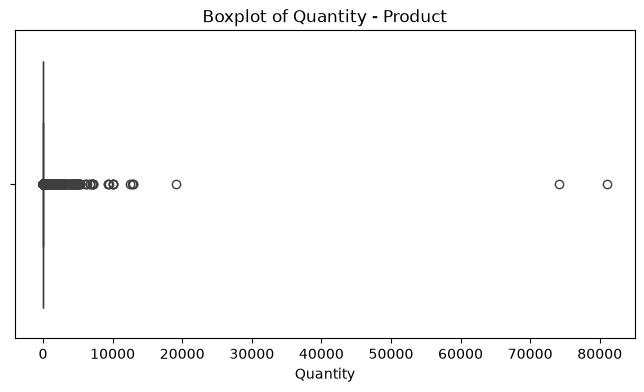

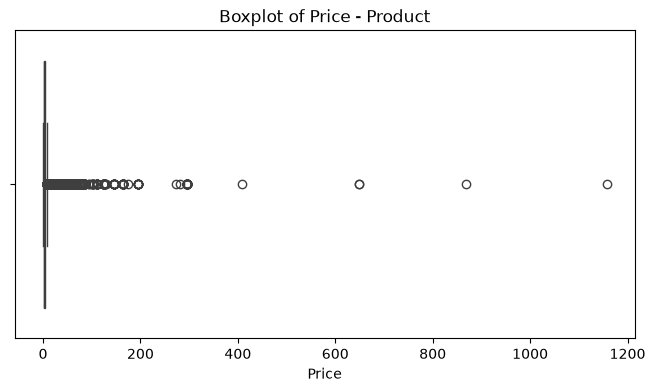

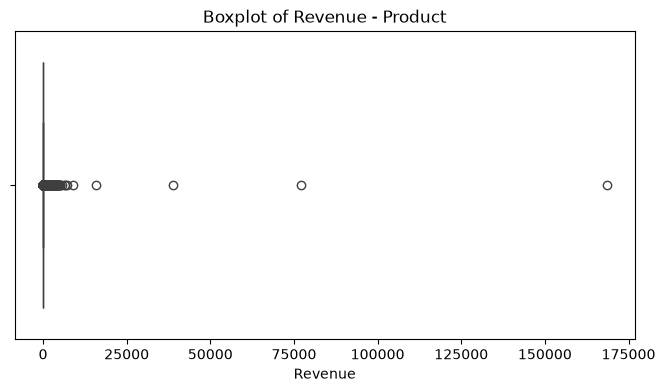

In [42]:
import matplotlib.pyplot as plt
import seaborn as sns

columns_to_plot = ["Quantity", "Price", "Revenue"]

for col in columns_to_plot:
    plt.figure(figsize=(8, 4))
    sns.boxplot(x=df_product[col])
    plt.title(f"Boxplot of {col} - Product")
    plt.xlabel(col)
    plt.show()

In [44]:
print("Kiểu dữ liệu InvoiceDate:", df_product["InvoiceDate"].dtype)
display(df_product[["InvoiceDate", "Revenue"]].head())

Kiểu dữ liệu InvoiceDate: datetime64[us]


,InvoiceDate,Revenue
0,2009-12-01 07:45:00,83.4
1,2009-12-01 07:45:00,81.0
2,2009-12-01 07:45:00,81.0
3,2009-12-01 07:45:00,100.8
4,2009-12-01 07:45:00,30.0


In [45]:
# Tạo cột ngày trong tuần
df_product["DayOfWeek"] = df_product["InvoiceDate"].dt.day_name()

display(df_product[["InvoiceDate", "DayOfWeek", "Revenue"]].head(10))

,InvoiceDate,DayOfWeek,Revenue
0,2009-12-01 07:45:00,Tuesday,83.4
1,2009-12-01 07:45:00,Tuesday,81.0
2,2009-12-01 07:45:00,Tuesday,81.0
3,2009-12-01 07:45:00,Tuesday,100.8
4,2009-12-01 07:45:00,Tuesday,30.0
5,2009-12-01 07:45:00,Tuesday,39.6
6,2009-12-01 07:45:00,Tuesday,30.0
7,2009-12-01 07:45:00,Tuesday,59.5
8,2009-12-01 07:46:00,Tuesday,30.6
9,2009-12-01 07:46:00,Tuesday,45.0


In [46]:
# Thứ tự các ngày trong tuần
day_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

# Tổng hợp dữ liệu theo ngày
day_analysis = df_product.groupby("DayOfWeek").agg(
    Total_Revenue=("Revenue", "sum"),
    Total_Orders=("Invoice", "nunique"),
    Total_Quantity=("Quantity", "sum")
)

# Sắp xếp đúng thứ tự ngày trong tuần
day_analysis = day_analysis.reindex(day_order)

# Tính tỷ trọng doanh thu
day_analysis["Revenue_Percentage"] = (
    day_analysis["Total_Revenue"] /
    df_product["Revenue"].sum() * 100
)

display(day_analysis.round(2))

,Total_Revenue,Total_Orders,Total_Quantity,Revenue_Percentage
DayOfWeek,,,,
Monday,3468619.94,6252,2049181,17.30
Tuesday,3961728.69,7148,2163942,19.76
Wednesday,3476999.18,7117,2046189,17.34
Thursday,4108004.01,8170,2368456,20.49
Friday,3211961.83,5993,1692968,16.02
Saturday,9803.05,30,5119,0.05
Sunday,1816066.76,4826,1042432,9.06


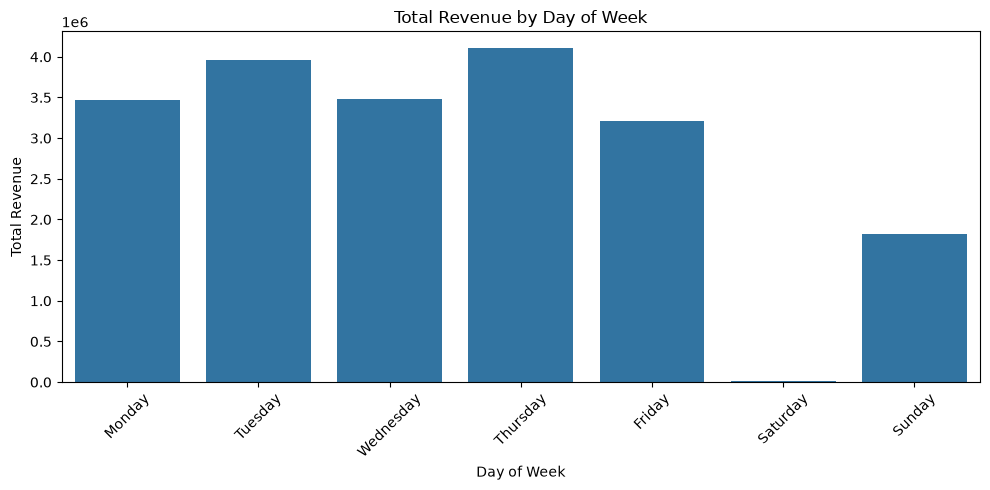

In [47]:
plt.figure(figsize=(10, 5))

sns.barplot(
    x=day_analysis.index,
    y=day_analysis["Total_Revenue"]
)

plt.title("Total Revenue by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Total Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

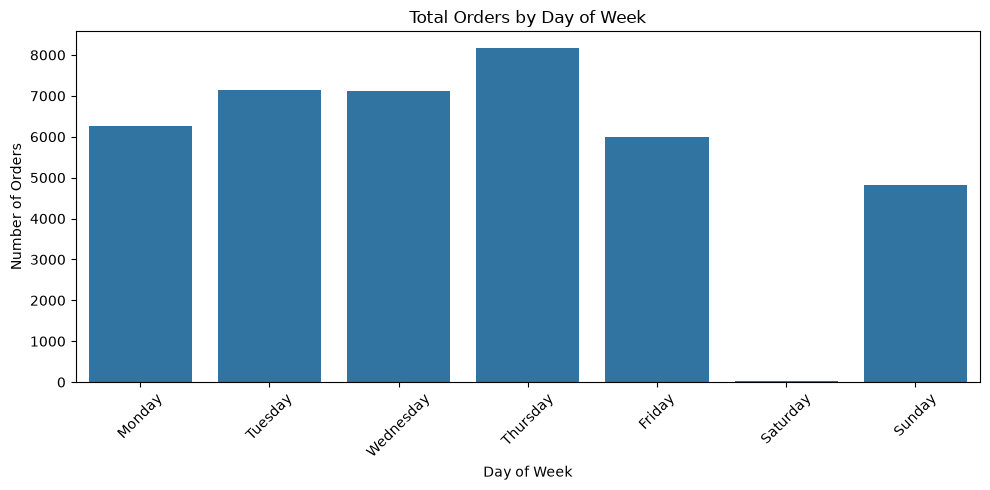

In [48]:
plt.figure(figsize=(10, 5))

sns.barplot(
    x=day_analysis.index,
    y=day_analysis["Total_Orders"]
)

plt.title("Total Orders by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [49]:
# Tổng hợp dữ liệu theo từng hóa đơn
df_orders = df_product.groupby("Invoice").agg(
    Order_Value=("Revenue", "sum"),
    Total_Quantity=("Quantity", "sum"),
    Number_of_Products=("Description", "nunique"),
    CustomerID=("Customer ID", "first")
).reset_index()

print("Kích thước dữ liệu Order:", df_orders.shape)

display(df_orders.head())

Kích thước dữ liệu Order: (39536, 5)


,Invoice,Order_Value,Total_Quantity,Number_of_Products,CustomerID
0,489434,505.30,166,8,13085.0
1,489435,145.80,60,4,13085.0
2,489436,630.33,193,19,13078.0
3,489437,310.75,145,23,15362.0
4,489438,2286.24,826,17,18102.0


In [50]:
# Thống kê giá trị đơn hàng
display(df_orders["Order_Value"].describe().round(2))

# Tính AOV và Median Order Value
aov = df_orders["Order_Value"].mean()
median_order_value = df_orders["Order_Value"].median()

print("Average Order Value (AOV):", round(aov, 2))
print("Median Order Value:", round(median_order_value, 2))

count     39536.00
mean        507.21
std        1488.48
min           0.19
25%         151.50
50%         302.63
75%         494.50
max      168469.60
Name: Order_Value, dtype: float64

Average Order Value (AOV): 507.21
Median Order Value: 302.63


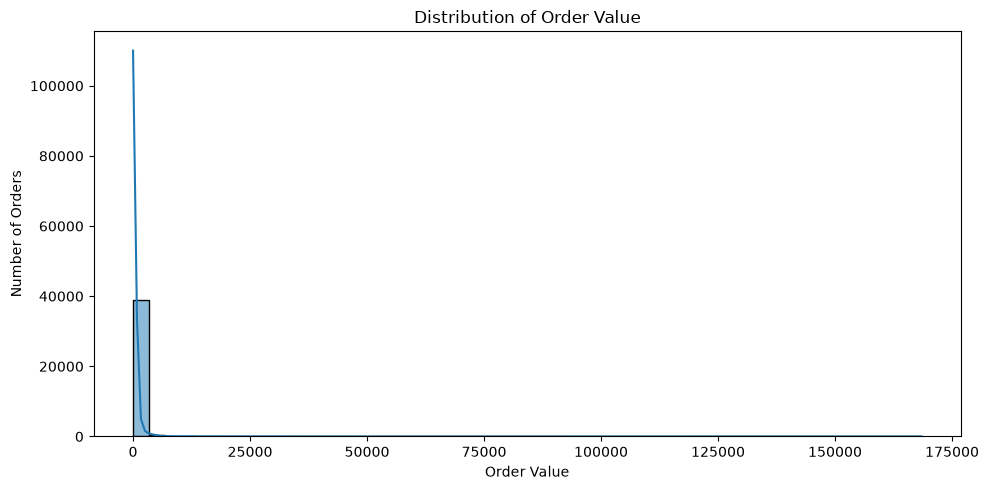

In [51]:
plt.figure(figsize=(10, 5))

sns.histplot(
    df_orders["Order_Value"],
    bins=50,
    kde=True
)

plt.title("Distribution of Order Value")
plt.xlabel("Order Value")
plt.ylabel("Number of Orders")
plt.tight_layout()
plt.show()

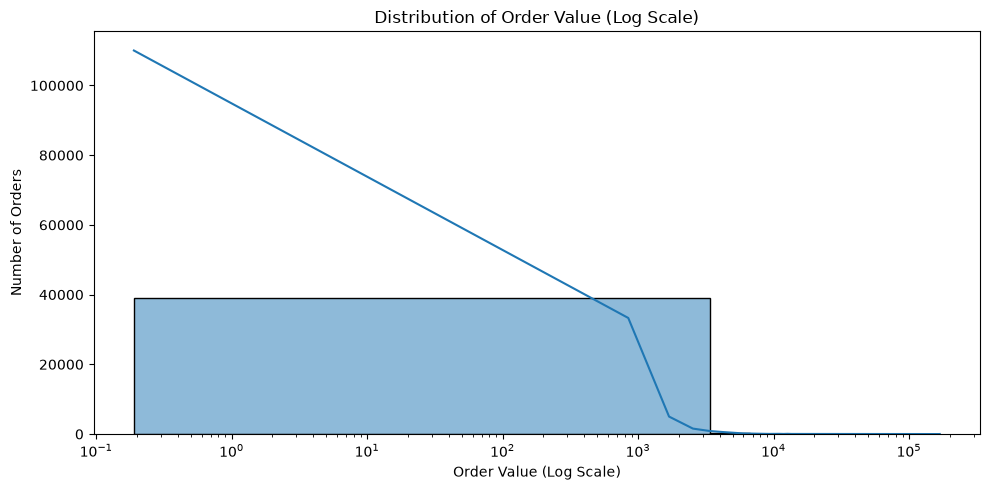

In [52]:
plt.figure(figsize=(10, 5))

sns.histplot(
    df_orders["Order_Value"],
    bins=50,
    kde=True
)

plt.xscale("log")

plt.title("Distribution of Order Value (Log Scale)")
plt.xlabel("Order Value (Log Scale)")
plt.ylabel("Number of Orders")

plt.tight_layout()
plt.show()

In [54]:
# Thống kê quy mô giỏ hàng
df_orders[["Total_Quantity", "Number_of_Products"]].describe()

,Total_Quantity,Number_of_Products
count,39536.000000,39536.000000
mean,287.542670,25.080939
std,1207.722366,42.230605
min,1.000000,1.000000
25%,68.000000,6.000000
50%,150.000000,15.000000
75%,293.000000,28.000000
max,87167.000000,1107.000000


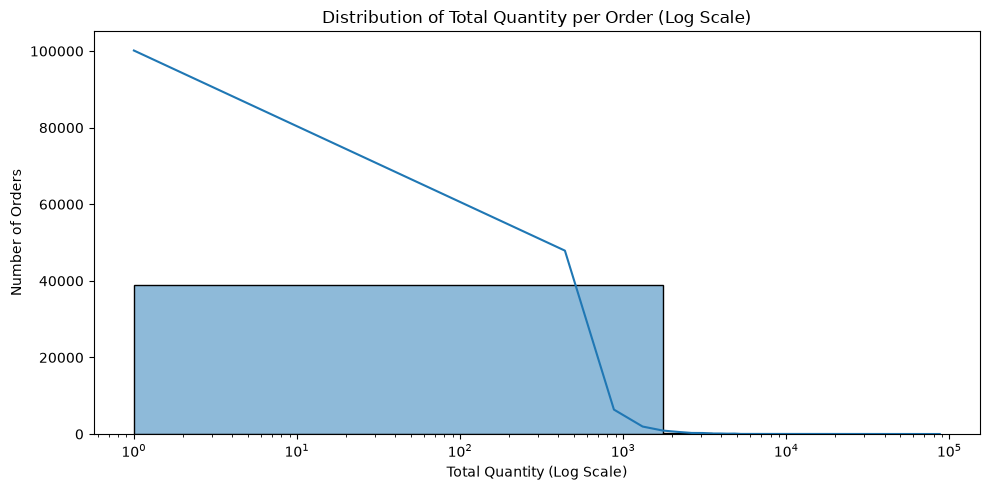

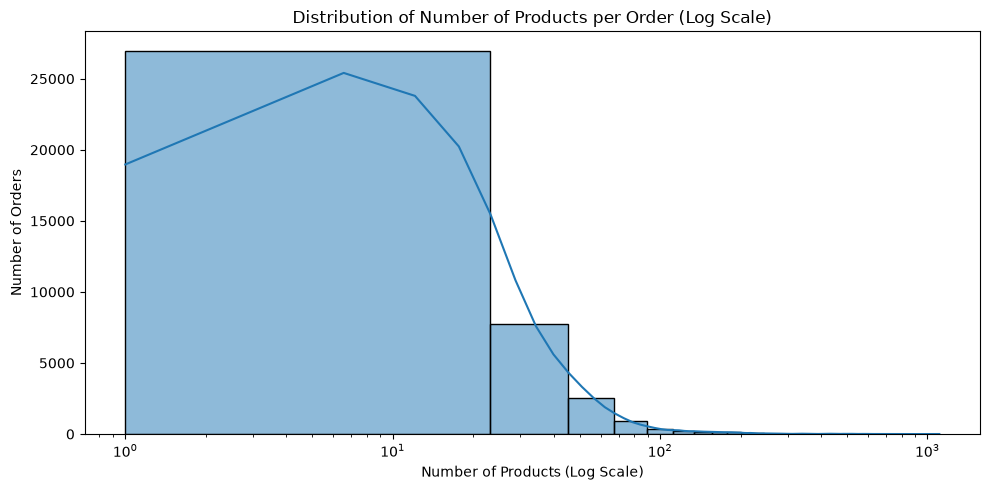

In [55]:
# Phân bố tổng số lượng hàng hóa mỗi đơn
plt.figure(figsize=(10, 5))
sns.histplot(df_orders["Total_Quantity"], bins=50, kde=True)
plt.xscale("log")
plt.title("Distribution of Total Quantity per Order (Log Scale)")
plt.xlabel("Total Quantity (Log Scale)")
plt.ylabel("Number of Orders")
plt.tight_layout()
plt.show()

# Phân bố số loại sản phẩm mỗi đơn
plt.figure(figsize=(10, 5))
sns.histplot(df_orders["Number_of_Products"], bins=50, kde=True)
plt.xscale("log")
plt.title("Distribution of Number of Products per Order (Log Scale)")
plt.xlabel("Number of Products (Log Scale)")
plt.ylabel("Number of Orders")
plt.tight_layout()
plt.show()

In [56]:
# Tính số đơn hàng của từng khách hàng
df_customer_frequency = df_orders.groupby("CustomerID").agg(
    Total_Orders=("Invoice", "nunique"),
    Total_Revenue=("Order_Value", "sum")
).reset_index()

df_customer_frequency.head()

,CustomerID,Total_Orders,Total_Revenue
0,12346.0,12,77556.46
1,12347.0,8,5633.32
2,12348.0,5,1658.40
3,12349.0,3,3678.69
4,12350.0,1,294.40


In [57]:
# Thống kê tần suất mua hàng
df_customer_frequency["Total_Orders"].describe()

count    5852.000000
mean        6.255981
std        12.752717
min         1.000000
25%         1.000000
50%         3.000000
75%         7.000000
max       373.000000
Name: Total_Orders, dtype: float64

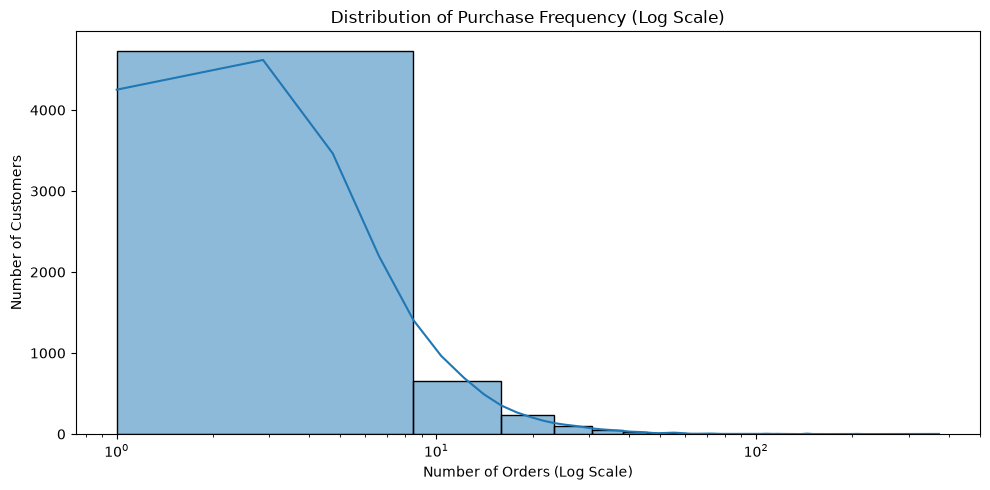

In [58]:
# Phân bố số đơn hàng của khách hàng
plt.figure(figsize=(10, 5))

sns.histplot(df_customer_frequency["Total_Orders"], bins=50, kde=True)

plt.xscale("log")
plt.title("Distribution of Purchase Frequency (Log Scale)")
plt.xlabel("Number of Orders (Log Scale)")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

In [59]:
# Tổng hợp các chỉ số KPI chính

total_revenue = df_product["Revenue"].sum()
total_orders = df_orders["Invoice"].nunique()
total_customers = df_customer_frequency["CustomerID"].nunique()
total_quantity = df_product["Quantity"].sum()
avg_order_value = df_orders["Order_Value"].mean()
avg_orders_per_customer = df_customer_frequency["Total_Orders"].mean()

kpi_summary = pd.DataFrame({
    "Metric": [
        "Total Revenue",
        "Total Orders",
        "Total Customers",
        "Total Quantity Sold",
        "Average Order Value",
        "Average Orders per Customer"
    ],
    "Value": [
        total_revenue,
        total_orders,
        total_customers,
        total_quantity,
        avg_order_value,
        avg_orders_per_customer
    ]
})

kpi_summary

,Metric,Value
0,Total Revenue,2.005318e+07
1,Total Orders,3.953600e+04
2,Total Customers,5.852000e+03
3,Total Quantity Sold,1.136829e+07
4,Average Order Value,5.072133e+02
5,Average Orders per Customer,6.255981e+00
